# Rewind & Amplify: a walkthrough

Grover's algorithm inside a quantum recurrent state machine (QRSM), in about a dozen cells. Every number here comes from a Qiskit circuit. It takes under a minute and needs no account.

**The problem.** A QRSM emits a click, or no click, at each step. To study a rare event you normally run it again and again and discard the runs that don't match.

**The plan.** Purify the machine so it can be rewound. Steer it so the event is common. Amplify locally. Verify by measuring.

In [1]:
import logging
import sys
sys.path.insert(0, "..")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

import numpy as np
from qiskit.quantum_info import Statevector

from qrsm_grover import QRSM, any_click, click_at, conditional_distribution, success_probability, total_variation
from qrsm_grover.amplify import amplified, hardware_amplified, steered_gamma
from qrsm_grover.fastsim import FastPurified, light_distribution, reflection_qubits

machine = QRSM()   # a driven emitter, one hidden defect, and a light that clicks
T = 6
print(machine)

QRSM(theta=0.6, gamma=0.2, phi=(0.45,), zeta=(0.3,))


## 1. The dynamic machine: measured and reset every step

This is the QRSM as it runs on a device. One light qubit, measured mid-circuit and reset. Here are two steps of it. A reset throws information away, so this circuit has no inverse, and Grover can't use it.

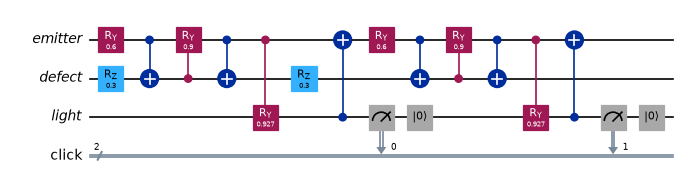

In [2]:
machine.dynamic(2).draw("mpl", fold=-1, scale=0.6)

## 2. Move 1: purify

Give every step a fresh light and measure nothing until the end. The click statistics can't change, and the whole run is now one reversible circuit A. Its state holds every click history at once:

$$A|0\rangle = \sum_y |m_y\rangle |y\rangle, \qquad \langle m_y | m_y \rangle = P(y)$$

So it should equal the exact model's branches, amplitude by amplitude.

In [3]:
A = machine.purified(T)
n = machine.n_memory
state = Statevector(A).data.reshape(2 ** T, 2 ** n)
print("qubits:", A.num_qubits)
print("largest amplitude difference from the exact model:", np.abs(state - machine.branches(T)).max())

qubits: 8
largest amplitude difference from the exact model: 3.855927796350635e-16


## 3. Grover on the machine's histories

The question: a click at step 6. Qiskit's own `grover_operator` builds each iteration from A and an oracle, and the circuit follows the textbook curve $P_r = \sin^2((2r+1)\theta)$.

In [4]:
question = click_at(T)
mask = question.mask(T)
probs = machine.history_probabilities(T)
p = probs[mask].sum()
oracle = question.oracle(n + T, list(range(n, n + T)))
print(f"p = {p:.4f}")
for r in range(4):
    d = (np.abs(Statevector(amplified(A, oracle, r)).data) ** 2).reshape(2 ** T, 2 ** n).sum(axis=1)
    print(f"r = {r}: hit rate {d[mask].sum():.4f}   theory {success_probability(p, r):.4f}   "
          f"distance from the exact conditional {total_variation(conditional_distribution(d, mask), conditional_distribution(probs, mask)):.1e}")

p = 0.0802
r = 0: hit rate 0.0802   theory 0.0802   distance from the exact conditional 1.8e-17
r = 1: hit rate 0.5757   theory 0.5757   distance from the exact conditional 9.6e-17
r = 2: hit rate 0.9818   theory 0.9818   distance from the exact conditional 3.5e-17
r = 3: hit rate 0.8193   theory 0.8193   distance from the exact conditional 1.1e-16


The last column is the important one. Amplification reweights without reshaping: inside the matching histories the relative odds never change. So an amplified shot is an exact conditional sample.

## 4. Move 2: steer

A click's Kraus operator is $\sin\alpha\, |0\rangle\langle 1|$ on the emitter. So turning up the emission at that step scales every history that clicks there by the same constant. The conditional answer can't change, and the chance can be set to exactly 1/4, where one iteration gives certainty.

In [5]:
steer = steered_gamma(p, machine.gamma)
print(f"steered emission at step {T}: {machine.gamma} -> {steer:.3f}")
K1, K1_steered = machine.kraus()[1], machine.kraus(gamma=steer)[1]
print("K1 scales by a constant:", np.abs(K1_steered - np.sqrt(steer / machine.gamma) * K1).max() < 1e-12)

fast = FastPurified(machine, T, [None] * (T - 1) + [steer])
d = light_distribution(dict(fast.amplify(mask, 1, None))[1], T, fast.dim)
print(f"one iteration: hit rate {d[mask].sum():.6f}, distance from the exact conditional "
      f"{total_variation(conditional_distribution(d, mask), conditional_distribution(probs, mask)):.1e}")

steered emission at step 6: 0.2 -> 0.623
K1 scales by a constant: True
one iteration: hit rate 1.000000, distance from the exact conditional 7.2e-17


## 5. Move 3: amplify locally

The reflection in Grover checks every qubit, and that gate grows with the record. We watch only the memory and the one light the question reads: 3 qubits, at any length. `reflection_qubits` names the choices, and Qiskit's `grover_operator` accepts them directly.

In [6]:
for kind in ("full", "memory", "memory+last-1"):
    rq = reflection_qubits(machine, T, kind)
    d = light_distribution(dict(fast.amplify(mask, 1, rq))[1], T, fast.dim)
    print(f"{kind:14s} watches {len(rq):2d} qubits: hit rate {d[mask].sum():.3f}, distance {total_variation(conditional_distribution(d, mask), conditional_distribution(probs, mask)):.3f}")

full           watches  8 qubits: hit rate 1.000, distance 0.000
memory         watches  2 qubits: hit rate 0.837, distance 0.133
memory+last-1  watches  3 qubits: hit rate 0.972, distance 0.052


## 6. On an IBM device model

Now compile for a real device layout and simulate its noise. This is what the resilient build buys: far fewer two-qubit gates, so better answers. The textbook build at its best r is on the left, and the resilient build on the right. (T = 3 here, so this takes seconds.)

In [7]:
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import fake_provider
from qrsm_grover.hardware import compile_best, history_experiment

backend = fake_provider.FakeKingston()
sim = AerSimulator.from_backend(backend)
T3 = 3
q3 = click_at(T3)
m3 = q3.mask(T3)
p3 = machine.history_probabilities(T3)[m3].sum()
builds = [("textbook, r = 3", history_experiment("t", machine, T3, q3, "full", 3)),
          ("steer + local, r = 1", history_experiment("s", machine, T3, q3, "memory+last-1", 1, steered_gamma(p3, machine.gamma)))]
for name, exp in builds:
    isa, info = compile_best(exp.circuit, backend, seeds=3)
    counts = sim.run(isa, shots=8192, seed_simulator=7).result().get_counts()
    hit = sum(c for bits, c in counts.items() if (int(bits, 2) >> (n + T3 - 1)) & 1) / 8192
    print(f"{name:22s} {info['two_qubit_gates']:3d} two-qubit gates, hit rate {hit:.3f}")

textbook, r = 3        213 two-qubit gates, hit rate 0.767


steer + local, r = 1    42 two-qubit gates, hit rate 0.906


## Where to go next

- `demo/demo.py`: the one-minute demo, including the keyword search.
- `demo/index.html`: an interactive lab.
- `docs/REPORT.md`: every result, with what we got wrong.
- `experiments/run_ibm.py`: run this on real IBM hardware with your own account.

At this size a classical sampler beats all of this. The report says why it could still matter at larger memories, and what we don't claim.